# AI Resume Screening System
**Sqrock IT Solutions — Data Science Internship, Phase 1, Task 3**

**Goal:** read a batch of resumes (PDF or TXT), compare each one with a job description using NLP, and produce a ranked shortlist with a match score (%).

**Pipeline:** Data collection (PDF → text) → NLP preprocessing → Feature extraction (TF-IDF / Bag of Words) → Matching (cosine similarity + keyword matching) → Ranking and shortlisting

**Data:** 14 fictional resumes from several professions (data science, web, data engineering, marketing, finance, HR, design) in a mix of PDF and TXT, plus 3 job descriptions. They are generated by `generate_sample_data.py`.

In [1]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from PyPDF2 import PdfReader
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity

import screener  # helper module with the same functions, used by the web app

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

## 1. Data collection: convert PDFs into text
PDFs are parsed page by page with **PyPDF2**, and TXT files are read directly.

In [2]:
RESUME_DIR = Path("data/resumes")
resumes = []
for path in sorted(RESUME_DIR.iterdir()):
    if path.suffix == ".pdf":
        reader = PdfReader(path)
        text = "\n".join(page.extract_text() or "" for page in reader.pages)
    else:
        text = path.read_text(encoding="utf-8")
    resumes.append({"file": path.name, "format": path.suffix[1:].upper(), "text": text})

resume_df = pd.DataFrame(resumes)
resume_df["characters"] = resume_df["text"].str.len()
print(resume_df["format"].value_counts().to_string())
resume_df[["file", "format", "characters"]]

format
PDF    8
TXT    6


,file,format,characters
0,anisa_leka.pdf,PDF,407
1,arben_kola.txt,TXT,680
2,besnik_cela.txt,TXT,412
3,dritan_basha.pdf,PDF,652
4,elira_hoxha.pdf,PDF,1019
5,erion_daci.pdf,PDF,695
6,ermal_gjoka.txt,TXT,567
7,fjona_zeqiri.txt,TXT,415
8,gentian_prifti.pdf,PDF,435
9,jonida_rama.pdf,PDF,585


In [3]:
print(resumes[4]["text"][:700])

Elira Hoxha
 elira.hoxha@example.com | +355 69 111 2233 | Tirana, Albania
SUMMARY
Data Scientist with 4 years of experience building machine learning models for retail and fintech.
Strong in Python, statistics and communicating insights to stakeholders.
SKILLS
Python, Pandas, NumPy, Scikit-learn, TensorFlow, SQL, PostgreSQL, Machine Learning, Deep
Learning, NLP, Data Visualization, Matplotlib, Seaborn, Power BI, Git, Docker, AWS, Statistics, A/B
Testing
EXPERIENCE
Data Scientist, FinNova Analytics (2022 - Present)
- Built a credit-risk classification model with XGBoost and Scikit-learn that reduced defaults by 12%.
- Designed A/B tests and statistical analyses for product pricing experiments


In [4]:
job_description = Path("data/job_descriptions/data_scientist.txt").read_text()
print(job_description)

Job Title: Data Scientist
We are hiring a Data Scientist to build machine learning models that drive business decisions.
Requirements:
- 2+ years of experience in data science or machine learning
- Strong Python skills with Pandas, NumPy and Scikit-learn
- Experience with SQL and relational databases such as PostgreSQL
- Knowledge of statistics, A/B testing and machine learning algorithms (regression, classification, clustering)
- Experience with deep learning frameworks such as TensorFlow or PyTorch is a plus
- NLP experience is a plus
- Data visualization with Matplotlib, Seaborn, Power BI or Tableau
- Familiarity with Git, Docker and cloud platforms (AWS)
- Strong communication skills to explain results to non-technical stakeholders
Education: Bachelor's or Master's degree in Computer Science, Statistics, Mathematics or a related field.



## 2. NLP preprocessing
Each document goes through these steps:
1. **Lowercase** the text
2. **Remove** emails, URLs, punctuation, digits and special characters
3. **Tokenize** into words
4. **Remove stopwords** (scikit-learn's English stopword list, 318 words)
5. **Stem** each token with NLTK's Porter stemmer (*building → build*, *models → model*)

In [5]:
stemmer = PorterStemmer()

def preprocess_verbose(text):
    steps = {}
    t = text.lower();                                        steps["1. lowercase"] = t
    t = re.sub(r"\S+@\S+|http\S+", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t);                         steps["2. clean"] = t
    tokens = t.split();                                      steps["3. tokens"] = tokens
    tokens = [w for w in tokens if w not in ENGLISH_STOP_WORDS and len(w) > 1]
    steps["4. no stopwords"] = tokens
    steps["5. stemmed"] = [stemmer.stem(w) for w in tokens]
    return steps

demo = preprocess_verbose("Built a credit-risk classification model with XGBoost and Scikit-learn that reduced defaults by 12%.")
for k, v in demo.items():
    print(f"{k:16s} → {v}")

1. lowercase     → built a credit-risk classification model with xgboost and scikit-learn that reduced defaults by 12%.
2. clean         → built a credit risk classification model with xgboost and scikit learn that reduced defaults by     
3. tokens        → ['built', 'a', 'credit', 'risk', 'classification', 'model', 'with', 'xgboost', 'and', 'scikit', 'learn', 'that', 'reduced', 'defaults', 'by']
4. no stopwords  → ['built', 'credit', 'risk', 'classification', 'model', 'xgboost', 'scikit', 'learn', 'reduced', 'defaults']
5. stemmed       → ['built', 'credit', 'risk', 'classif', 'model', 'xgboost', 'scikit', 'learn', 'reduc', 'default']


In [6]:
resume_df["clean"] = resume_df["text"].apply(screener.preprocess)
clean_jd = screener.preprocess(job_description)
resume_df["tokens"] = resume_df["clean"].str.split().str.len()
resume_df[["file", "tokens", "clean"]].head()

,file,tokens,clean
0,anisa_leka.pdf,36,anisa leka summari senior account year experi financi report audit skill acc...
1,arben_kola.txt,70,arben kola profil machin learn engin year experi nlp comput vision technic s...
2,besnik_cela.txt,41,besnik cela summari ui ux design year experi design mobil web product skill ...
3,dritan_basha.pdf,65,dritan basha summari frontend develop year experi build respons web applic s...
4,elira_hoxha.pdf,105,elira hoxha tirana albania summari data scientist year experi build machin l...


## 3. Feature extraction: text → numbers
- **Bag of Words** counts how often each word (and word pair) appears.
- **TF-IDF** weights each word by how distinctive it is. Words that appear in every resume (like *experience*) get low weight, and rare, specific words (like *tensorflow*) get high weight. This is the recommended method.

TF-IDF matrix: (15, 1005) | BoW matrix: (15, 1005)


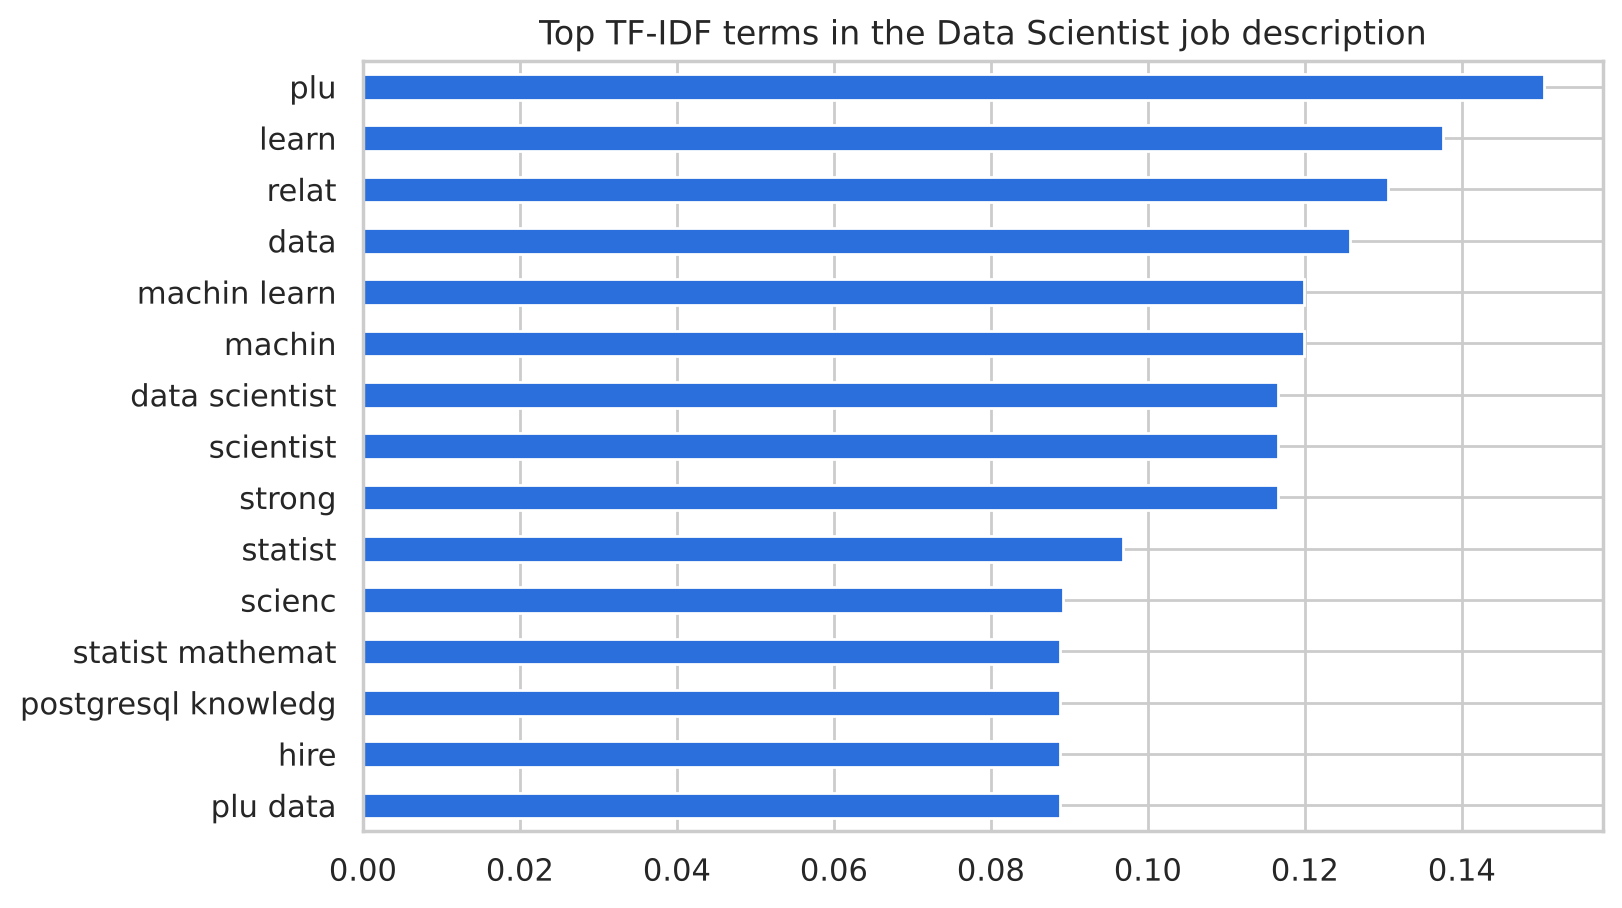

In [7]:
corpus = [clean_jd] + resume_df["clean"].tolist()

tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X_tfidf = tfidf.fit_transform(corpus)
bow = CountVectorizer(ngram_range=(1, 2))
X_bow = bow.fit_transform(corpus)
print("TF-IDF matrix:", X_tfidf.shape, "| BoW matrix:", X_bow.shape)

# Most important terms in the job description according to TF-IDF
jd_weights = pd.Series(X_tfidf[0].toarray().ravel(), index=tfidf.get_feature_names_out())
jd_weights.sort_values(ascending=False).head(15).plot(kind="barh", color="#2a6fdb", figsize=(8, 5))
plt.gca().invert_yaxis()
plt.title("Top TF-IDF terms in the Data Scientist job description")
plt.show()

## 4. Matching algorithm
### 4.1 Cosine similarity
Cosine similarity measures the angle between the job description vector and each resume vector. 1 means identical word usage and 0 means nothing in common.

In [8]:
resume_df["cosine_tfidf"] = cosine_similarity(X_tfidf[0], X_tfidf[1:]).ravel()
resume_df["cosine_bow"] = cosine_similarity(X_bow[0], X_bow[1:]).ravel()
resume_df[["file", "cosine_tfidf", "cosine_bow"]].sort_values("cosine_tfidf", ascending=False)

,file,cosine_tfidf,cosine_bow
4,elira_hoxha.pdf,0.282903,0.532119
5,erion_daci.pdf,0.189212,0.421147
9,jonida_rama.pdf,0.156730,0.336782
1,arben_kola.txt,0.133426,0.363770
13,sara_mehmeti.pdf,0.109692,0.297396
6,ermal_gjoka.txt,0.076695,0.250425
8,gentian_prifti.pdf,0.039948,0.124435
11,liridona_kastrati.txt,0.037325,0.122806
12,megi_dervishi.txt,0.037001,0.122009
7,fjona_zeqiri.txt,0.015333,0.088578


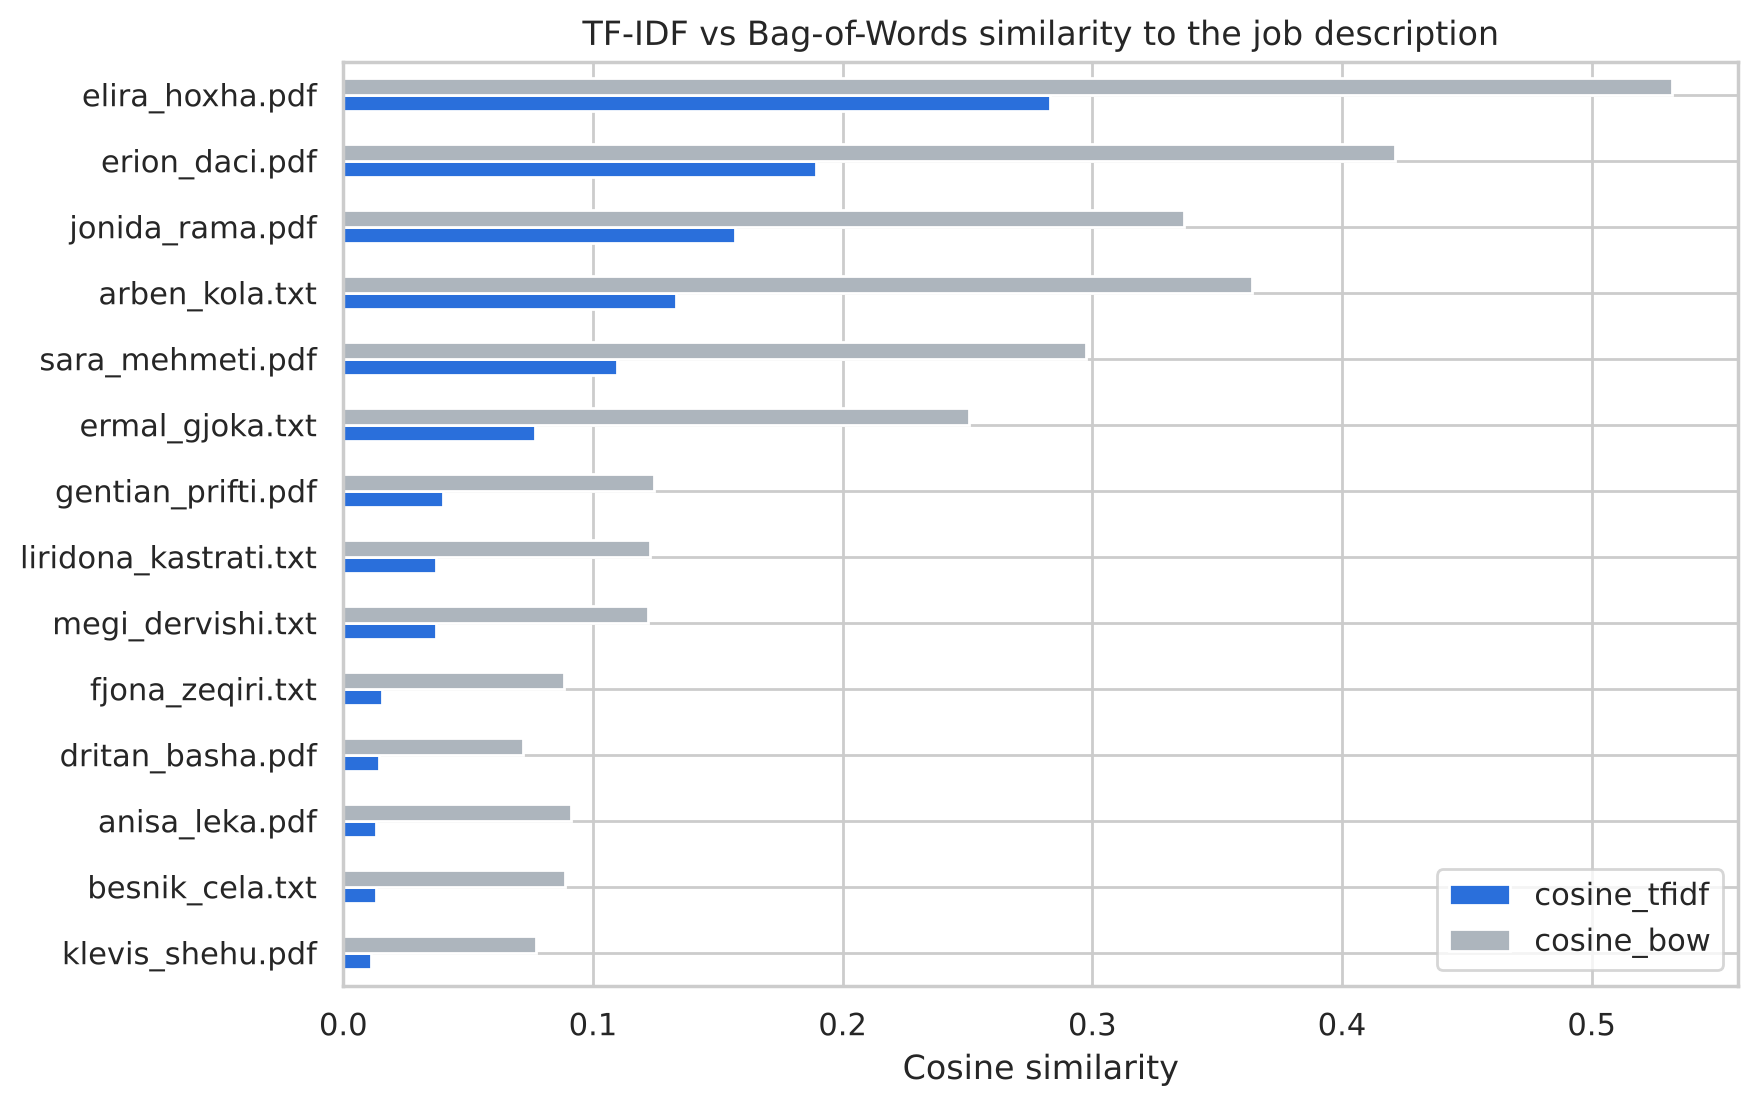

Rank correlation between TF-IDF and BoW: 0.947


In [9]:
ax = resume_df.set_index("file")[["cosine_tfidf", "cosine_bow"]].sort_values("cosine_tfidf") \
    .plot(kind="barh", figsize=(9, 6), color=["#2a6fdb", "#adb5bd"])
ax.set(title="TF-IDF vs Bag-of-Words similarity to the job description", xlabel="Cosine similarity", ylabel="")
plt.show()
print("Rank correlation between TF-IDF and BoW:",
      round(resume_df["cosine_tfidf"].corr(resume_df["cosine_bow"], method="spearman"), 3))

Both methods agree on the overall order. TF-IDF separates relevant from irrelevant resumes more sharply because it down-weights generic words.

### 4.2 Keyword (skill) matching
Cosine similarity alone can be fooled by long resumes or shared filler words, so I also extract **concrete skills** using a vocabulary of about 90 technical and soft skills (with aliases such as *sklearn → scikit-learn*). Then I measure what share of the job's required skills each resume covers.

25 skills required by the job:
 ['a/b testing', 'aws', 'classification', 'clustering', 'communication', 'data visualization', 'deep learning', 'docker', 'git', 'machine learning', 'matplotlib', 'nlp', 'numpy', 'pandas', 'postgresql', 'power bi', 'python', 'pytorch', 'regression', 'scikit-learn', 'seaborn', 'sql', 'statistics', 'tableau', 'tensorflow']


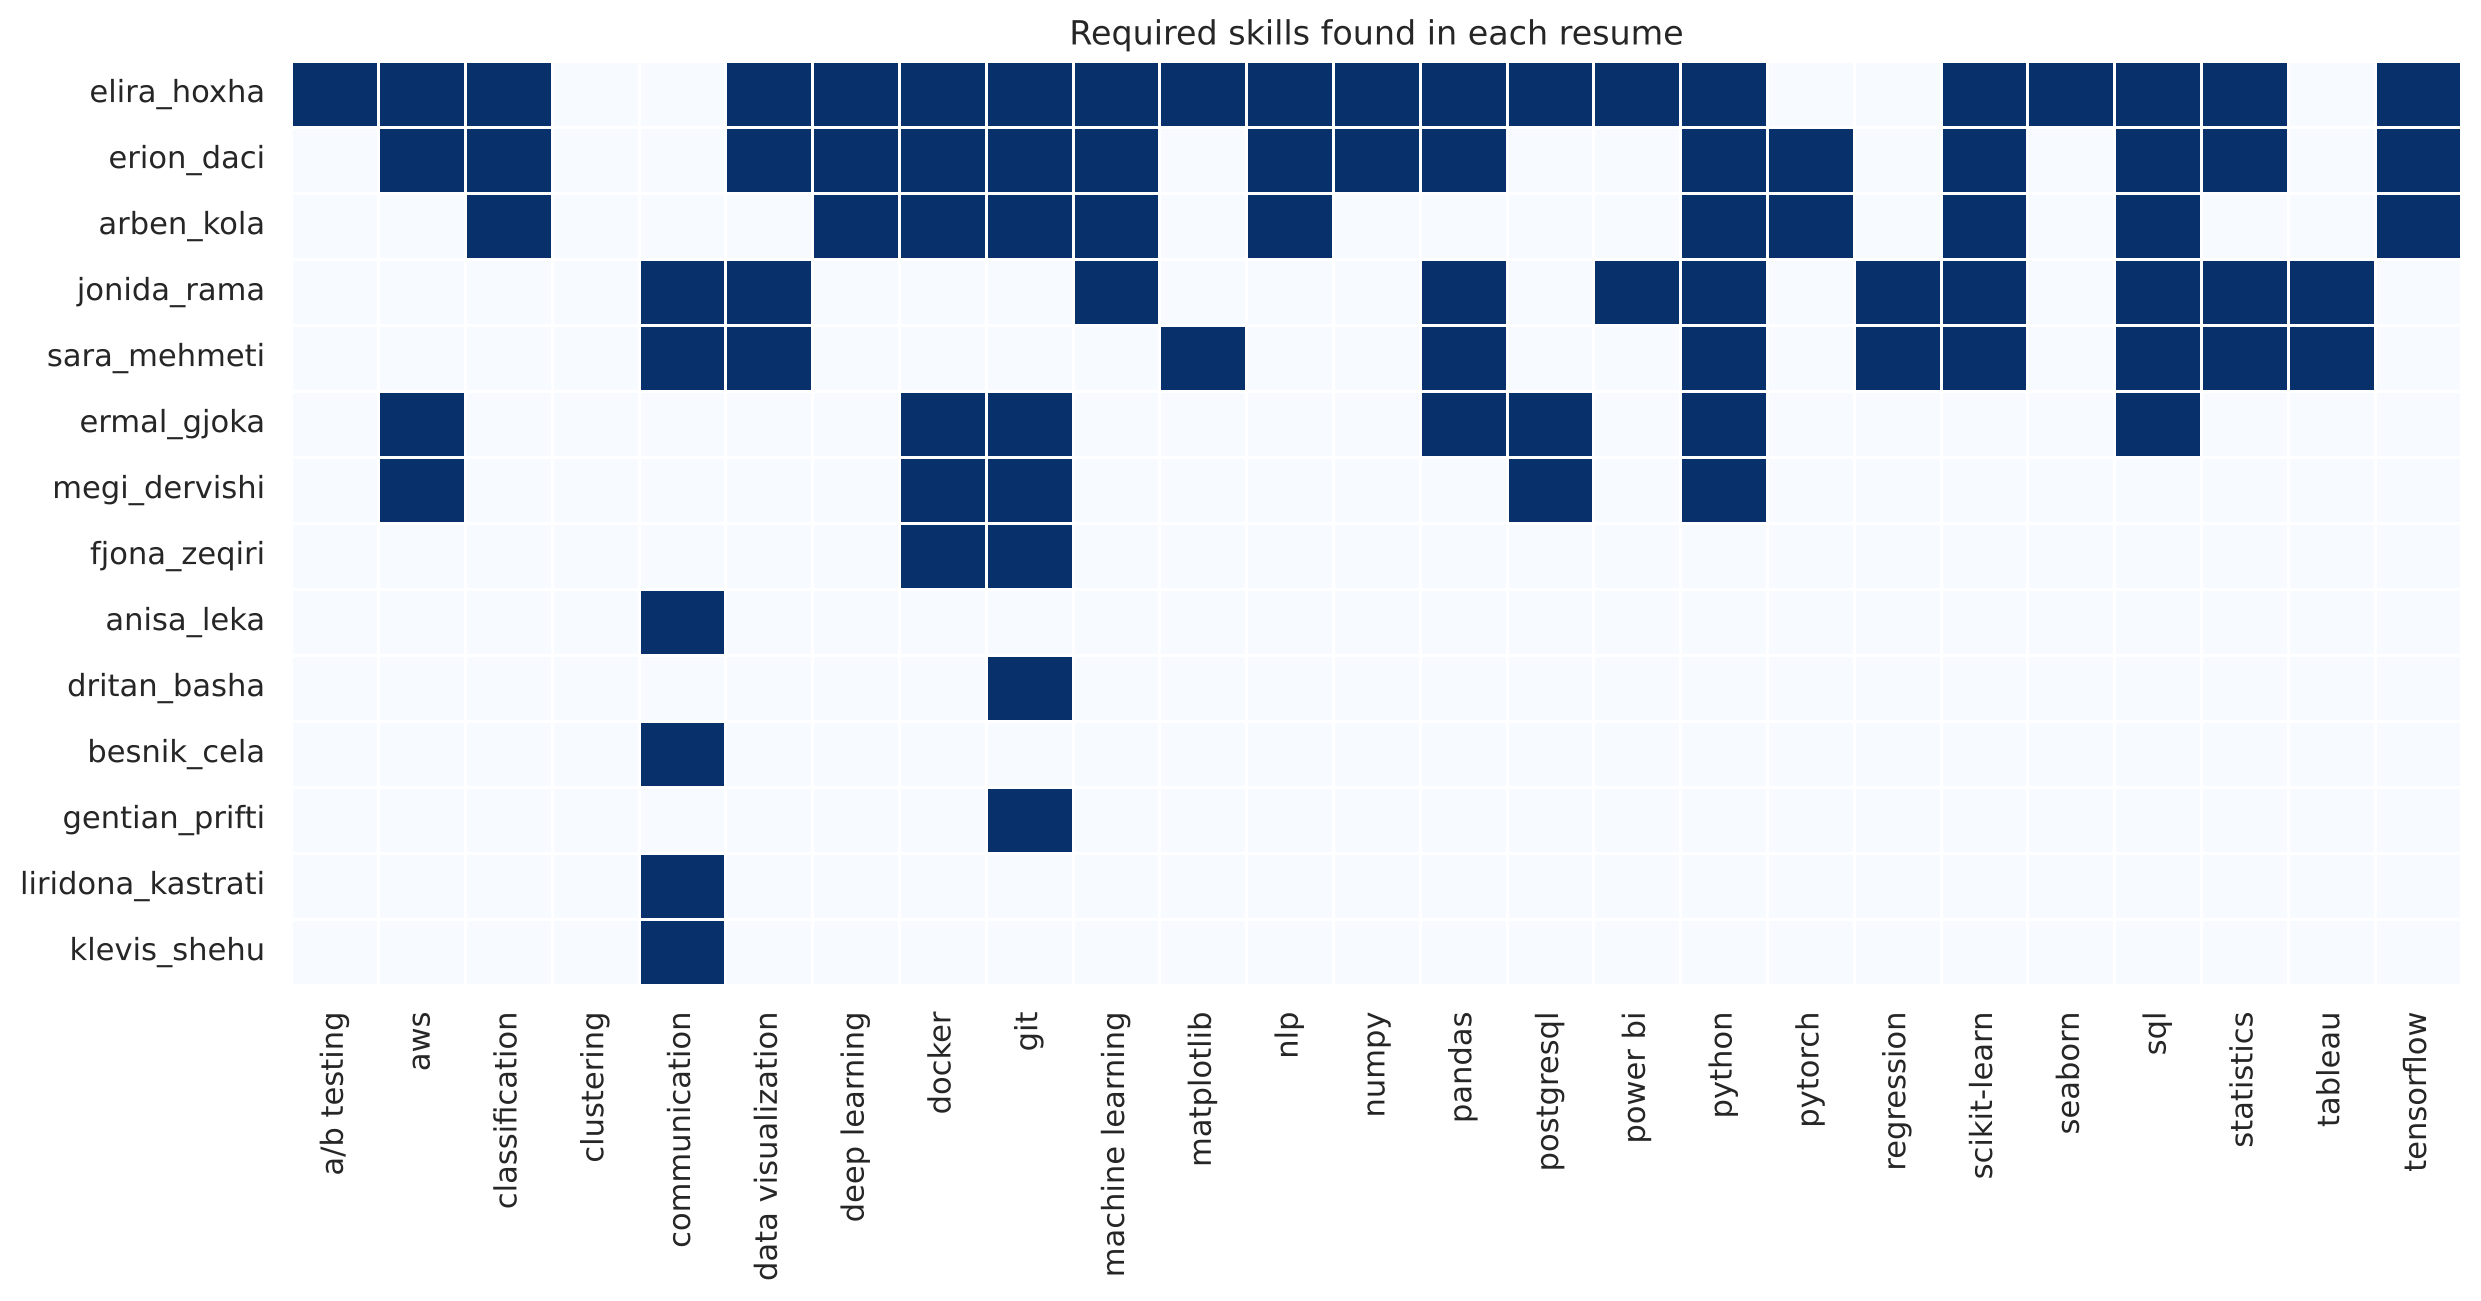

In [10]:
jd_skills = screener.extract_skills(job_description)
print(f"{len(jd_skills)} skills required by the job:\n", sorted(jd_skills))

resume_df["skills"] = resume_df["text"].apply(screener.extract_skills)
resume_df["skill_coverage"] = resume_df["skills"].apply(lambda s: len(s & jd_skills) / len(jd_skills))

# Heatmap: which resume has which required skill
matrix = pd.DataFrame({f: {sk: int(sk in s) for sk in sorted(jd_skills)}
                       for f, s in zip(resume_df["file"].str.replace(r"\.\w+$", "", regex=True), resume_df["skills"])}).T
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(14, 6))
sns.heatmap(matrix, cmap="Blues", cbar=False, linewidths=0.5, linecolor="white")
plt.title("Required skills found in each resume")
plt.show()

### 4.3 Final NLP similarity score
**Match % = 60% × text similarity + 40% × skill coverage**

Text similarity is rescaled so the closest resume in the batch scores 100. This makes the score relative to the applicant pool, the same way a recruiter compares candidates.

In [11]:
ranked = screener.rank_resumes(job_description, resumes, method="tfidf", w_similarity=0.6, threshold=50)
ranked[["Rank", "Candidate", "Match %", "Cosine similarity", "Skill coverage %", "Years exp.", "Status"]]

,Rank,Candidate,Match %,Cosine similarity,Skill coverage %,Years exp.,Status
0,1,Elira Hoxha,92.0,0.283,80.0,4.0,✅ Shortlisted
1,2,Erion Daci,65.7,0.189,64.0,6.0,✅ Shortlisted
2,3,Jonida Rama,50.8,0.157,44.0,2.0,✅ Shortlisted
3,4,Arben Kola,45.9,0.133,44.0,3.0,❌ Rejected
4,5,Sara Mehmeti,39.3,0.110,40.0,1.0,❌ Rejected
5,6,Ermal Gjoka,27.5,0.077,28.0,4.0,❌ Rejected
6,7,Megi Dervishi,15.8,0.037,20.0,3.0,❌ Rejected
7,8,Gentian Prifti,10.1,0.040,4.0,1.0,❌ Rejected
8,9,Liridona Kastrati,9.5,0.037,4.0,5.0,❌ Rejected
9,10,Fjona Zeqiri,6.5,0.015,8.0,2.0,❌ Rejected


## 5. Ranking system and shortlist

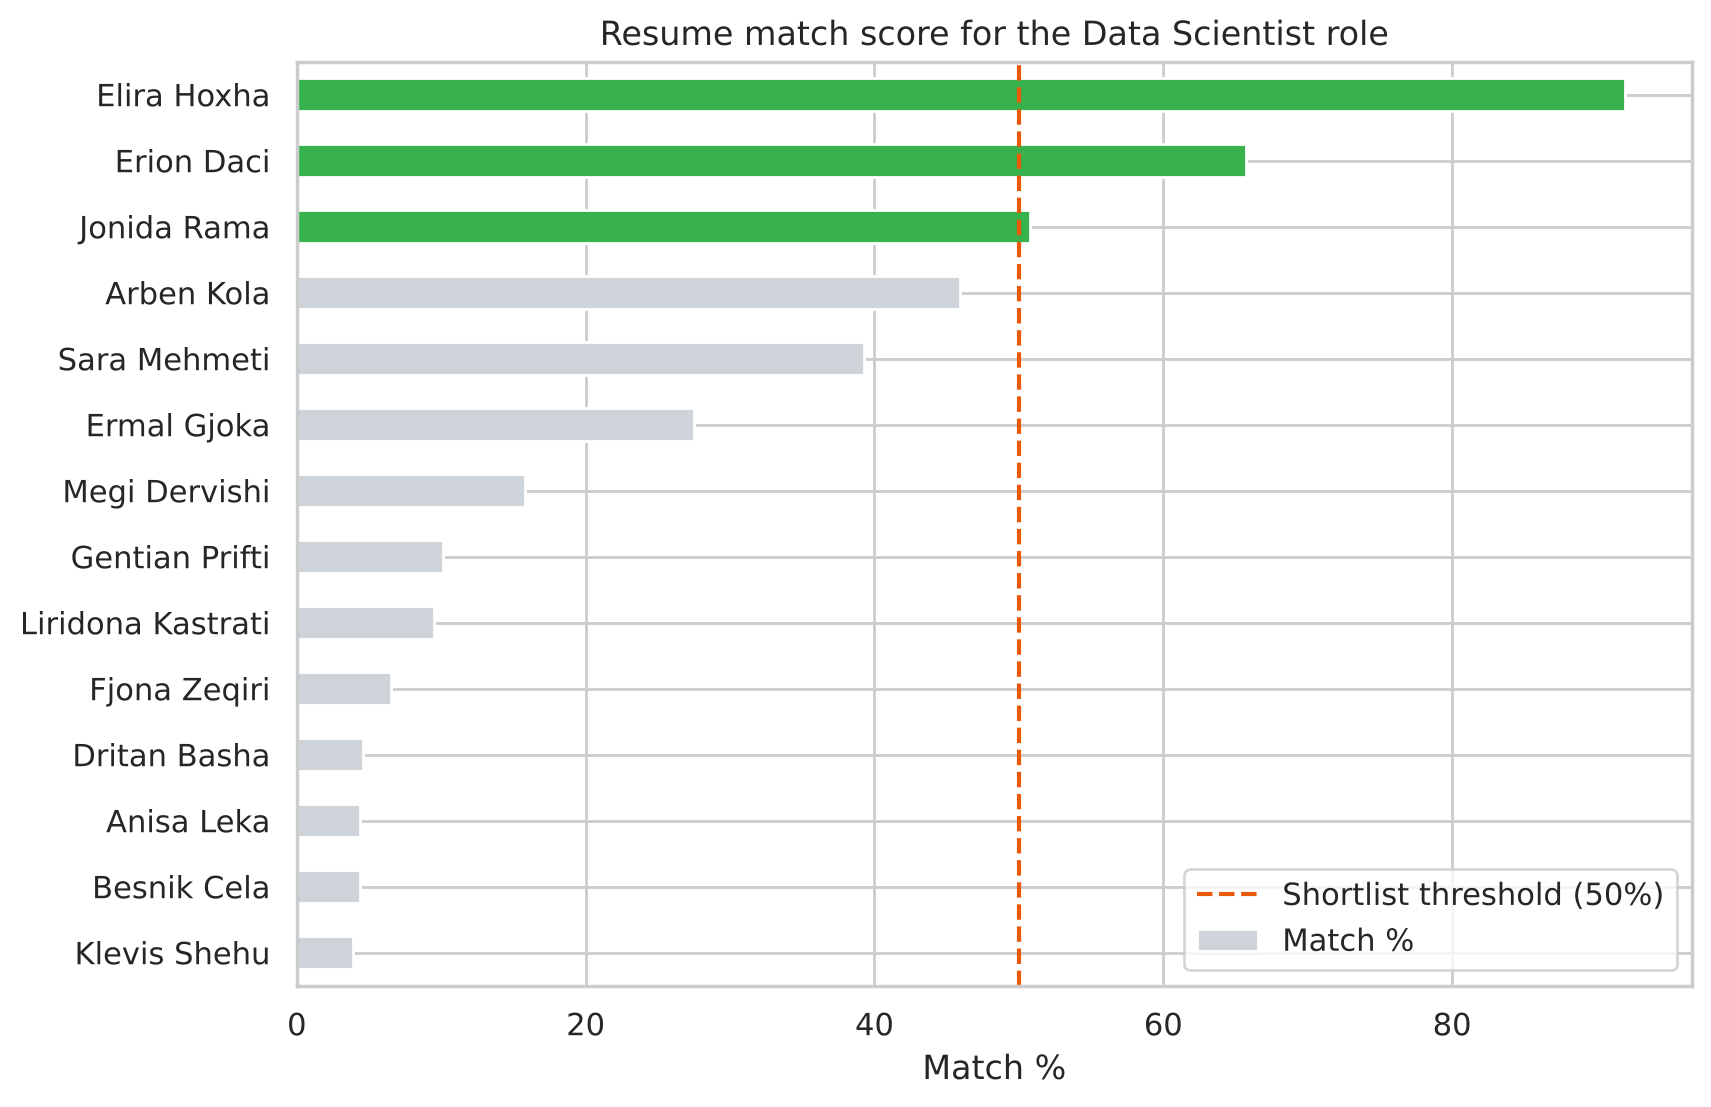

In [12]:
colors = ["#37b24d" if s.startswith("✅") else "#ced4da" for s in ranked["Status"]]
ax = ranked.set_index("Candidate")["Match %"][::-1].plot(kind="barh", color=colors[::-1], figsize=(9, 6))
ax.axvline(50, color="#e8590c", ls="--", label="Shortlist threshold (50%)")
ax.set(title="Resume match score for the Data Scientist role", xlabel="Match %", ylabel="")
ax.legend()
plt.show()

In [13]:
shortlist = ranked[ranked["Status"].str.startswith("✅")]
print(f"Shortlisted {len(shortlist)} of {len(ranked)} candidates:\n")
shortlist[["Rank", "Candidate", "Email", "Match %", "Matched skills", "Missing skills"]]

Shortlisted 3 of 14 candidates:



,Rank,Candidate,Email,Match %,Matched skills,Missing skills
0,1,Elira Hoxha,elira.hoxha@example.com,92.0,"a/b testing, aws, classification, data visualization, deep learning, docker,...","clustering, communication, pytorch, regression, tableau"
1,2,Erion Daci,erion.daci@example.com,65.7,"aws, classification, data visualization, deep learning, docker, git, machine...","a/b testing, clustering, communication, matplotlib, postgresql, power bi, re..."
2,3,Jonida Rama,jonida.rama@example.com,50.8,"communication, data visualization, machine learning, pandas, power bi, pytho...","a/b testing, aws, classification, clustering, deep learning, docker, git, ma..."


## 6. Does it generalise to other roles?
The same resumes are screened against two other job descriptions. A good system should surface completely different candidates for each role.

In [14]:
summary = {}
for jd_file in sorted(Path("data/job_descriptions").glob("*.txt")):
    r = screener.rank_resumes(jd_file.read_text(), resumes)
    summary[jd_file.stem.replace("_", " ").title()] = (r.head(3)["Candidate"] + " (" + r.head(3)["Match %"].astype(str) + "%)").tolist()
pd.DataFrame(summary, index=["#1", "#2", "#3"])

,Data Engineer,Data Scientist,Frontend Developer
#1,Ermal Gjoka (100.0%),Elira Hoxha (92.0%),Dritan Basha (97.3%)
#2,Elira Hoxha (26.7%),Erion Daci (65.7%),Gentian Prifti (67.6%)
#3,Arben Kola (26.2%),Jonida Rama (50.8%),Megi Dervishi (41.6%)


## 7. Conclusion
- I built a full NLP screening pipeline: PDF parsing → cleaning, tokenization, stopword removal and stemming → TF-IDF vectors → cosine similarity plus skill matching → ranked shortlist.
- For each of the three roles, the top-ranked candidates are exactly the people whose background fits. Unrelated profiles (HR, accounting, marketing) score below 10% on technical roles.
- Combining **semantic similarity** with **explicit skill coverage** makes the score explainable. The recruiter sees *which* skills matched and which are missing.
- **Limitations:** TF-IDF matches words, not meaning (for example, *"neural networks"* vs *"deep learning"*), and the skill vocabulary is hand-made.
- **Next steps:** sentence embeddings (e.g. Sentence-BERT) for semantic matching, section-aware parsing (experience vs education), and bias checks so names and genders never influence the score.